# Ex 10 — Sentiment Analysis

**Dataset:** Article Dataset 2 (BBC news)  
**Method:** VADER lexicon scoring  
**Reg No:** URK24CS1021

In [1]:
print("URK24CS1021")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()
df = pd.read_csv("bbc-text-1.csv")
df.head()

URK24CS1021


,category,text
0,tech,tv future in the hands of viewers with home theatre syst...
1,business,worldcom boss left books alone former worldcom boss be...
2,sport,tigers wary of farrell gamble leicester say they will ...
3,sport,yeading face newcastle in fa cup premiership side newcas...
4,entertainment,ocean s twelve raids box office ocean s twelve the crim...


In [2]:
print("URK24CS1021")

df.shape, df.isnull().sum().sum(), df.duplicated().sum()

URK24CS1021


((2225, 2), np.int64(0), np.int64(99))

In [3]:
print("URK24CS1021")

# the same article is in the file more than once
df = df.drop_duplicates().reset_index(drop=True)
df["category"].value_counts()

URK24CS1021


category
sport            504
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64

### How VADER scores text

In [4]:
print("URK24CS1021")

vader.polarity_scores("The team played brilliantly and won the final")

URK24CS1021


{'neg': 0.0, 'neu': 0.331, 'pos': 0.669, 'compound': 0.8779}

In [5]:
print("URK24CS1021")

vader.polarity_scores("The team did not play well and lost the final")

URK24CS1021


{'neg': 0.468, 'neu': 0.532, 'pos': 0.0, 'compound': -0.631}

### A whole article is too long to score in one go

In [6]:
print("URK24CS1021")

sample = df.sample(300, random_state=1021)
whole = sample["text"].map(lambda t: vader.polarity_scores(t)["compound"])
(whole.abs() > 0.95).mean()

URK24CS1021


np.float64(0.5966666666666667)

In [7]:
print("URK24CS1021")

# score 25 words at a time and average
def article_score(text, size=25):
    w = text.split()
    parts = [" ".join(w[i:i + size]) for i in range(0, len(w), size)]
    return np.mean([vader.polarity_scores(p)["compound"] for p in parts])

df["score"] = df["text"].map(article_score)
df["score"].describe().round(3)

URK24CS1021


count    2126.000
mean        0.115
std         0.221
min        -0.591
25%        -0.028
50%         0.118
75%         0.253
max         0.894
Name: score, dtype: float64

In [8]:
print("URK24CS1021")

def label(score):
    if score >= 0.05:
        return "positive"
    if score <= -0.05:
        return "negative"
    return "neutral"

df["sentiment"] = df["score"].map(label)
df["sentiment"].value_counts()

URK24CS1021


sentiment
positive    1355
negative     482
neutral      289
Name: count, dtype: int64

URK24CS1021


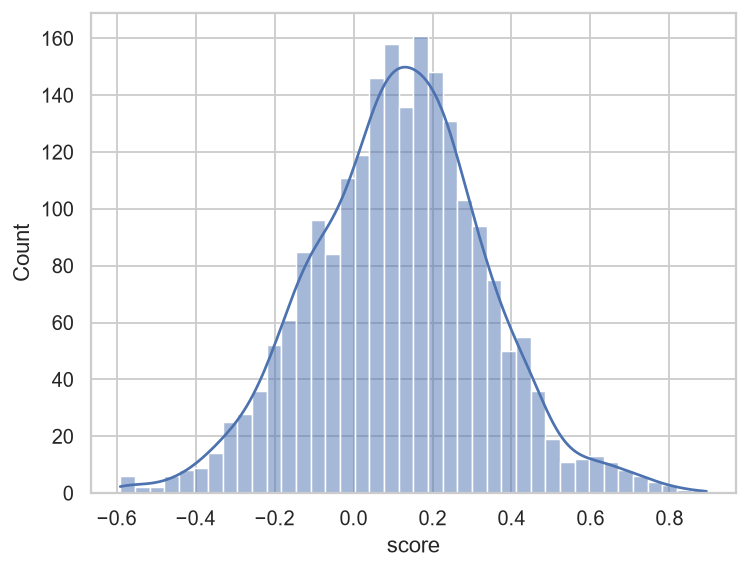

In [9]:
print("URK24CS1021")

sns.histplot(df["score"], bins=40, kde=True)
plt.show()

### Does sentiment depend on the kind of article?

In [10]:
print("URK24CS1021")

df.groupby("category")["score"].mean().round(3).sort_values()

URK24CS1021


category
politics         0.017
business         0.064
tech             0.116
sport            0.173
entertainment    0.211
Name: score, dtype: float64

URK24CS1021


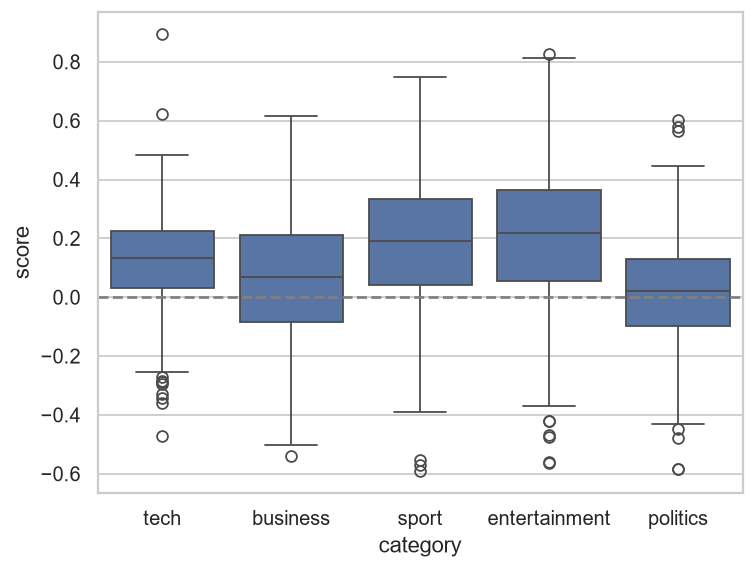

In [11]:
print("URK24CS1021")

sns.boxplot(data=df, x="category", y="score")
plt.axhline(0, color='grey', linestyle='--')
plt.show()